# SYNAPTA | Relatório de Felicidade Mundial (2019)

Versão: versão final, em testes.

## 1. Introdução

Este projeto analisa a felicidade de 156 países em 2019. A proposta é conferir os dados, comparar os países mais e menos felizes e observar a relação da felicidade com seis indicadores.

Pergunta principal: quais indicadores têm mais relação com a felicidade?

Uma relação entre dois dados não significa que um cause o outro.

## 2. Preparação e leitura do arquivo

A análise utiliza o arquivo `2019.csv` e as bibliotecas Pandas, Matplotlib e Seaborn.

No Colab, clique em Ambiente de execução > Executar tudo e envie o `2019.csv` quando solicitado.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 2019.csv to 2019.csv


In [ ]:
# Lendo o arquivo original de 2019 (enviado na célula anterior)
df = pd.read_csv("2019.csv")
print("Arquivo carregado com sucesso!")

Arquivo carregado com sucesso!


In [ ]:
# Definindo os indicadores uma única vez, para usar em todas as análises
fatores = [
    "GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption"
]
colunas_analise = ["Score"] + fatores
colunas_numericas = df.select_dtypes(include="number").columns

# Conferindo se as colunas esperadas estão presentes
colunas_necessarias = ["Overall rank", "Country or region"] + colunas_analise
faltando = [col for col in colunas_necessarias if col not in df.columns]
if faltando:
    raise ValueError(f"O arquivo CSV não contém as colunas esperadas: {faltando}")

## 3. Conhecendo os dados

Nesta etapa, são conferidas as primeiras linhas, o tamanho da tabela e os tipos de dados.

In [ ]:
df.head()

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


### O que significa cada coluna

| Coluna | Significado |
|---|---|
| `Overall rank` | Posição do país no ranking de felicidade. |
| `Country or region` | Nome do país ou região. |
| `Score` | Nota de felicidade do país. |
| `GDP per capita` | Indicador ligado à renda e à economia. |
| `Social support` | Apoio social percebido pelas pessoas. |
| `Healthy life expectancy` | Indicador relacionado à expectativa de vida saudável. |
| `Freedom to make life choices` | Liberdade percebida para fazer escolhas. |
| `Generosity` | Indicador relacionado à generosidade. |
| `Perceptions of corruption` | Indicador ligado à percepção de corrupção. |

Os seis fatores são indicadores do conjunto de dados, não medidas diretas de causa da felicidade.

In [ ]:
print("quantidade de linhas: ", df.shape[0])
print("quantidade de colunas: ", df.shape[1])

quantidade de linhas:  156
quantidade de colunas:  9


In [ ]:
print(df.columns)

Index(['Overall rank', 'Country or region', 'Score', 'GDP per capita',
       'Social support', 'Healthy life expectancy',
       'Freedom to make life choices', 'Generosity',
       'Perceptions of corruption'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


## 4. Conferindo os dados

Antes das análises, é feita uma busca por dados vazios, repetições, números negativos e zeros.

In [ ]:
df.isnull().sum()

,0
Overall rank,0
Country or region,0
Score,0
GDP per capita,0
Social support,0
Healthy life expectancy,0
Freedom to make life choices,0
Generosity,0
Perceptions of corruption,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print("Paises diferentes: ", df["Country or region"].nunique())
print("Paises repetidos: ", df["Country or region"].duplicated().sum())

Paises diferentes:  156
Paises repetidos:  0


In [ ]:
# Verificando valores negativos nas colunas numéricas
valores_negativos = (df[colunas_numericas] < 0).sum()
print("Valores negativos por coluna:")
print(valores_negativos)

Valores negativos por coluna:
Overall rank                    0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
dtype: int64


In [ ]:
# Contando valores iguais a zero em cada coluna numérica
zeros_por_coluna = (df[colunas_numericas] == 0).sum()
print("Quantidade de valores zerados por coluna:")
print(zeros_por_coluna)

Quantidade de valores zerados por coluna:
Overall rank                    0
Score                           0
GDP per capita                  1
Social support                  1
Healthy life expectancy         1
Freedom to make life choices    1
Generosity                      1
Perceptions of corruption       1
dtype: int64


In [ ]:
# Identificando países com valores zerados

for coluna in colunas_numericas:
    paises_zero = df.loc[df[coluna] == 0, "Country or region"]

    if len(paises_zero) > 0:
        print(f"\nColuna: {coluna}")
        print(paises_zero.to_list())


Coluna: GDP per capita
['Somalia']

Coluna: Social support
['Central African Republic']

Coluna: Healthy life expectancy
['Swaziland']

Coluna: Freedom to make life choices
['Afghanistan']

Coluna: Generosity
['Greece']

Coluna: Perceptions of corruption
['Moldova']


In [ ]:
# Criando uma cópia para investigar sem alterar os dados originais
df_auditoria = df.copy()

# A verificação considera apenas os seis indicadores socioeconômicos
df_auditoria["Possui_zero"] = (df_auditoria[fatores] == 0).any(axis=1)

print("Registros com pelo menos um zero:", df_auditoria["Possui_zero"].sum())
print("Registros sem zeros:", (~df_auditoria["Possui_zero"]).sum())

display(df_auditoria.loc[
    df_auditoria["Possui_zero"],
    ["Country or region"] + fatores + ["Possui_zero"]
])

Registros com pelo menos um zero: 6
Registros sem zeros: 150


,Country or region,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Possui_zero
70,Moldova,0.685,1.328,0.739,0.245,0.181,0.000,True
81,Greece,1.181,1.156,0.999,0.067,0.000,0.034,True
111,Somalia,0.000,0.698,0.268,0.559,0.243,0.270,True
134,Swaziland,0.811,1.149,0.000,0.313,0.074,0.135,True
153,Afghanistan,0.350,0.517,0.361,0.000,0.158,0.025,True
154,Central African Republic,0.026,0.000,0.105,0.225,0.235,0.035,True


### Resultado da conferência

Seis países apresentaram pelo menos um zero: Moldova, Greece, Somalia, Swaziland, Afghanistan e Central African Republic. Os outros 150 não tiveram zeros nesses indicadores. Não foram encontrados números negativos.

Os zeros foram mantidos, pois não é possível confirmar se representam valores reais ou dados não registrados. Esses resultados se referem ao `2019.csv` usado aqui.

## 5. Resumo dos números

São apresentados média, mediana, desvio-padrão, mínimo e máximo. A posição no ranking (`Overall rank`) não entra nessa comparação.

In [ ]:
# Calculando estatísticas descritivas do Score e dos seis fatores
estatisticas = df[colunas_analise].describe().T

# Exibindo os resultados
print("Estatísticas descritivas:")
display(estatisticas)

Estatísticas descritivas:


,count,mean,std,min,25%,50%,75%,max
Score,156.0,5.407096,1.113120,2.853,4.54450,5.3795,6.18450,7.769
GDP per capita,156.0,0.905147,0.398389,0.000,0.60275,0.9600,1.23250,1.684
Social support,156.0,1.208814,0.299191,0.000,1.05575,1.2715,1.45250,1.624
Healthy life expectancy,156.0,0.725244,0.242124,0.000,0.54775,0.7890,0.88175,1.141
Freedom to make life choices,156.0,0.392571,0.143289,0.000,0.30800,0.4170,0.50725,0.631
Generosity,156.0,0.184846,0.095254,0.000,0.10875,0.1775,0.24825,0.566
Perceptions of corruption,156.0,0.110603,0.094538,0.000,0.04700,0.0855,0.14125,0.453


## 6. Países mais e menos felizes

A comparação considera os dez países com maiores e menores notas de felicidade.

### Entendendo a média e a mediana

A média do `Score` é de aproximadamente 5,407. Ela representa a soma das notas dividida pelos 156 países. A mediana é de cerca de 5,380: metade das notas fica abaixo desse valor e metade fica acima. As duas medidas ajudam a entender o resultado geral.

In [ ]:
# 10 países com as maiores pontuações
top_10 = df.nlargest(10, "Score")

print("10 países com maior pontuação de felicidade:")
display(top_10[["Overall rank", "Country or region", "Score"]])


# 10 países com as menores pontuações
bottom_10 = df.nsmallest(10, "Score")

print("10 países com menor pontuação de felicidade:")
display(bottom_10[["Overall rank", "Country or region", "Score"]])

10 países com maior pontuação de felicidade:


,Overall rank,Country or region,Score
0,1,Finland,7.769
1,2,Denmark,7.600
2,3,Norway,7.554
3,4,Iceland,7.494
4,5,Netherlands,7.488
5,6,Switzerland,7.480
6,7,Sweden,7.343
7,8,New Zealand,7.307
8,9,Canada,7.278
9,10,Austria,7.246


10 países com menor pontuação de felicidade:


,Overall rank,Country or region,Score
155,156,South Sudan,2.853
154,155,Central African Republic,3.083
153,154,Afghanistan,3.203
152,153,Tanzania,3.231
151,152,Rwanda,3.334
150,151,Yemen,3.380
149,150,Malawi,3.410
148,149,Syria,3.462
147,148,Botswana,3.488
146,147,Haiti,3.597


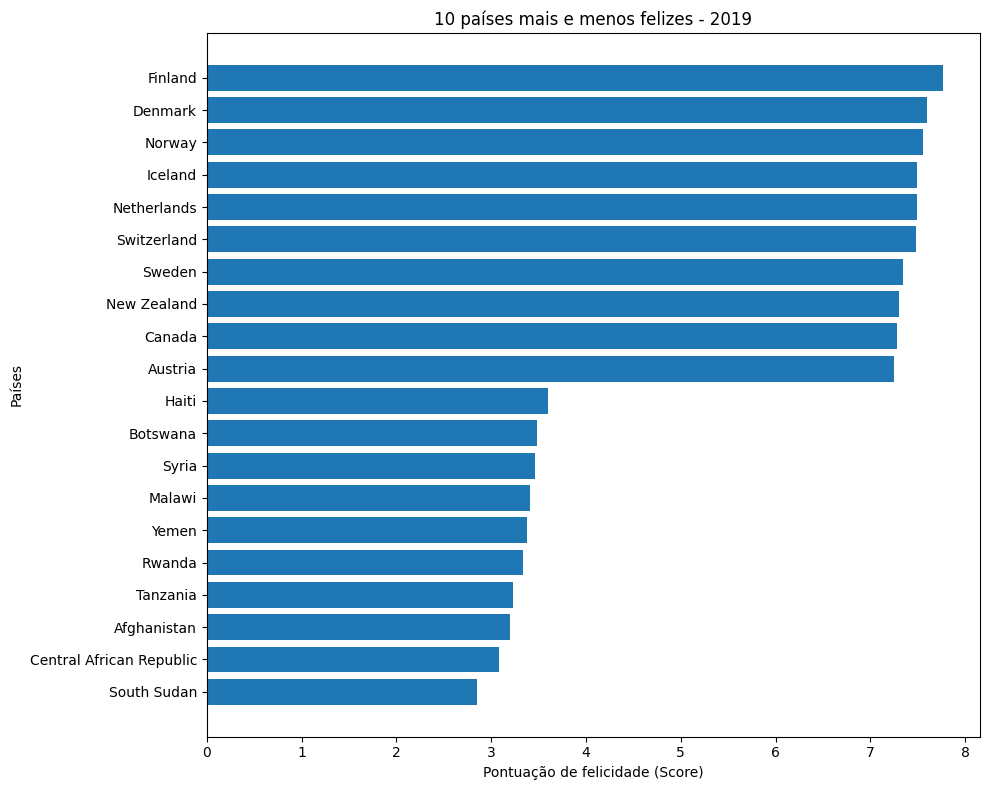

In [ ]:
# Juntando os dois grupos e ordenando pela pontuação
comparacao = pd.concat([top_10, bottom_10]).sort_values("Score")

# Criando o gráfico horizontal
plt.figure(figsize=(10, 8))
plt.barh(comparacao["Country or region"], comparacao["Score"])
plt.title("10 países mais e menos felizes - 2019")
plt.xlabel("Pontuação de felicidade (Score)")
plt.ylabel("Países")
plt.tight_layout()
plt.show()

### Comparando os países

Em 2019, a Finlândia ficou em primeiro lugar, com 7,769 pontos, e o Sudão do Sul ficou em último, com 2,853. A diferença foi de 4,916 pontos.

Entre os primeiros aparecem principalmente países europeus. Entre os últimos, predominam países da África e da Ásia. O ranking sozinho não explica essas diferenças.

### Sobre o gráfico do ranking

O gráfico mostra a nota de felicidade dos dez países mais bem colocados e dos dez últimos. No eixo horizontal está o `Score`; no vertical, os países.

## 7. Relação entre os indicadores e a felicidade

A correlação de Pearson é utilizada para medir a relação linear de cada indicador com a nota de felicidade (`Score`).

O resultado vai de -1 a +1. Valores positivos indicam que os dados tendem a subir juntos; negativos, que um tende a cair quando o outro sobe. Perto de zero, a relação linear é fraca.

Correlação não prova causa e efeito.

In [ ]:
# Matriz de correlação incluindo o Score e os seis fatores
matriz_corr = df[colunas_analise].corr(method="pearson")

# Exibindo apenas a correlação de cada fator com o Score
# (o Score não é comparado consigo mesmo nesta tabela)
correlacao_score = matriz_corr["Score"].drop("Score").sort_values(ascending=False)
print("Correlação de cada indicador com a pontuação de felicidade:")
display(correlacao_score.to_frame(name="Correlação com Score"))

Correlação de cada indicador com a pontuação de felicidade:


,Correlação com Score
GDP per capita,0.793883
Healthy life expectancy,0.779883
Social support,0.777058
Freedom to make life choices,0.566742
Perceptions of corruption,0.385613
Generosity,0.075824


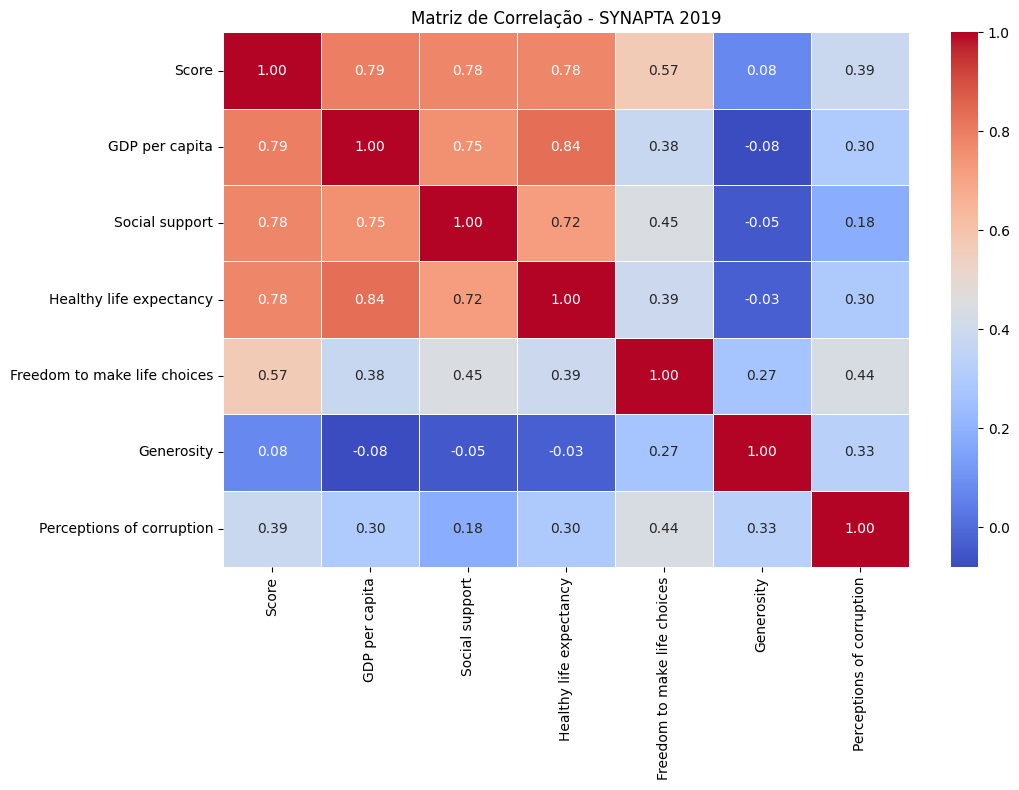

In [ ]:
# Representação visual de todas as correlações estudadas
plt.figure(figsize=(11, 8))
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlação - SYNAPTA 2019")
plt.tight_layout()
plt.show()

### O que a correlação mostrou

O PIB per capita teve a maior correlação com a felicidade (0,794), seguido da expectativa de vida saudável (0,780) e do apoio social (0,777).

Depois vieram liberdade para fazer escolhas (0,567), percepção de corrupção (0,386) e generosidade (0,076).

Esses números mostram relações entre os dados, não causas da felicidade.

### Sobre o mapa de correlação

O gráfico mostra como a felicidade e os indicadores se relacionam. As cores e os números ajudam a identificar relações positivas, negativas ou fracas.

## 8. Comparando os indicadores dos dois grupos

São comparadas as médias dos seis indicadores entre os dez países mais felizes e os dez menos felizes.

In [ ]:
# Calculando a média dos seis fatores em cada grupo
medias_top = top_10[fatores].mean()
medias_bottom = bottom_10[fatores].mean()

# Criando a tabela comparativa
comparacao_medias = pd.DataFrame({
    "Países mais felizes": medias_top,
    "Países menos felizes": medias_bottom
})
comparacao_medias["Diferença"] = (
    comparacao_medias["Países mais felizes"] - comparacao_medias["Países menos felizes"]
)

display(comparacao_medias.round(3))

,Países mais felizes,Países menos felizes,Diferença
GDP per capita,1.387,0.398,0.989
Social support,1.544,0.662,0.882
Healthy life expectancy,1.018,0.426,0.592
Freedom to make life choices,0.579,0.229,0.350
Generosity,0.274,0.219,0.055
Perceptions of corruption,0.319,0.123,0.196


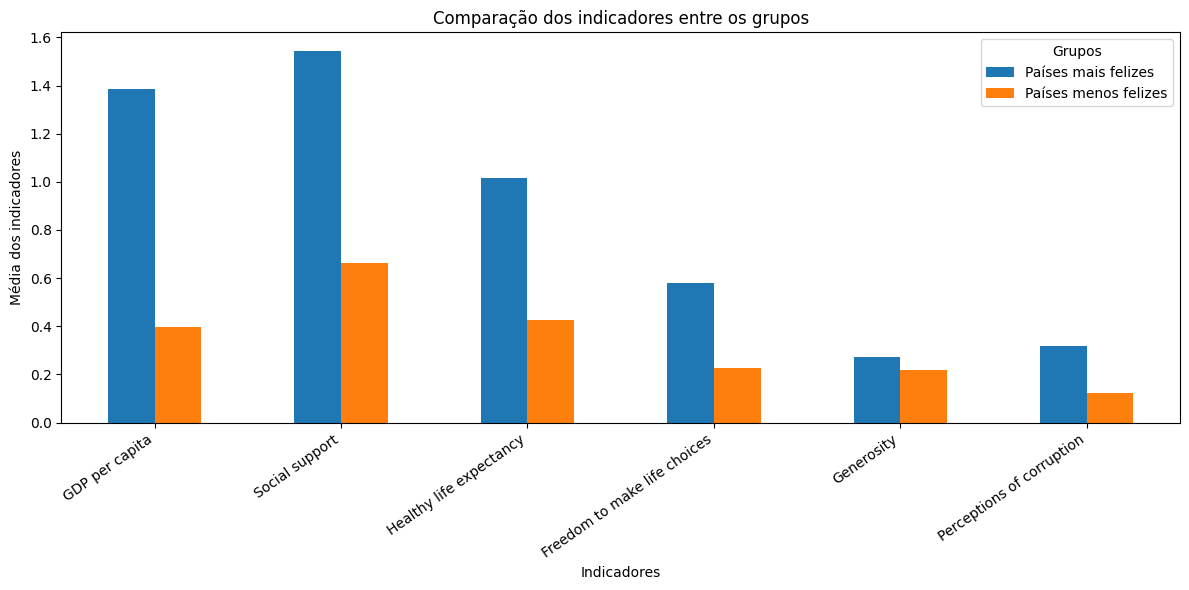

In [ ]:
# Criando gráfico de comparação
comparacao_medias[
    ["Países mais felizes", "Países menos felizes"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparação dos indicadores entre os grupos")
plt.xlabel("Indicadores")
plt.ylabel("Média dos indicadores")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Grupos")
plt.tight_layout()
plt.show()

### O que mudou de um grupo para o outro

Os dez países mais felizes tiveram médias maiores nos seis indicadores.

A diferença entre as médias foi de 0,989 no PIB per capita, 0,882 no apoio social, 0,592 na expectativa de vida saudável e 0,350 na liberdade de escolha.

Na percepção de corrupção, a diferença foi de 0,196; na generosidade, de 0,055. Como os indicadores têm escalas diferentes, uma diferença maior não significa maior importância.

### Sobre o gráfico das médias

O gráfico compara as médias dos seis indicadores nos dois grupos de países. Cada par de barras mostra um mesmo indicador, facilitando a comparação.

A comparação usa apenas os dez países de cada ponta do ranking. As diferenças não provam causa e efeito.

## 9. Olhando melhor a percepção de corrupção

Esta etapa apresenta o indicador por país e compara as médias.

In [ ]:
# Conferindo os valores de corrupção nos dois grupos

print("PAÍSES MAIS FELIZES")
display(
    top_10[["Country or region", "Perceptions of corruption"]]
)

print("\nPAÍSES MENOS FELIZES")
display(
    bottom_10[["Country or region", "Perceptions of corruption"]]
)

PAÍSES MAIS FELIZES


,Country or region,Perceptions of corruption
0,Finland,0.393
1,Denmark,0.410
2,Norway,0.341
3,Iceland,0.118
4,Netherlands,0.298
5,Switzerland,0.343
6,Sweden,0.373
7,New Zealand,0.380
8,Canada,0.308
9,Austria,0.226



PAÍSES MENOS FELIZES


,Country or region,Perceptions of corruption
155,South Sudan,0.091
154,Central African Republic,0.035
153,Afghanistan,0.025
152,Tanzania,0.147
151,Rwanda,0.411
150,Yemen,0.077
149,Malawi,0.089
148,Syria,0.141
147,Botswana,0.100
146,Haiti,0.110


### Resultados sobre a percepção de corrupção

A correlação com a felicidade foi de 0,386. A média foi de 0,319 nos dez países mais felizes e 0,123 nos dez menos felizes, uma diferença de 0,196.

Neste arquivo, valores maiores indicam uma percepção mais favorável quanto à ausência de corrupção generalizada. Isso vale para a média dos grupos, não para todos os países individualmente. A diferença não prova um efeito sobre a felicidade.

## 10. Conclusões

1. A Finlândia teve a maior nota (7,769) e o Sudão do Sul, a menor (2,853).
2. A diferença entre os dois foi de 4,916 pontos.
3. O PIB per capita teve a maior correlação com a felicidade (0,794).
4. Expectativa de vida saudável (0,780) e apoio social (0,777) também tiveram correlações altas.
5. A generosidade teve a menor correlação linear (0,076).
6. Os dez países mais felizes tiveram médias maiores nos seis indicadores.

Assim, PIB per capita, saúde e apoio social foram os indicadores mais relacionados à felicidade nesses dados. Isso não prova que sejam suas causas.

## 11. Limitações e fontes

- A análise considera apenas o ano de 2019.
- Correlação não prova causa e efeito.
- A comparação dos grupos considera só os dez primeiros e os dez últimos países.
- Seis registros com zeros foram mantidos, mas seu significado ainda precisa ser confirmado.
- Os indicadores usam escalas diferentes.

### Fonte

- World Happiness Report 2019: https://worldhappiness.report/ed/2019/
- Arquivo usado: `2019.csv`. A origem exata desta cópia ainda precisa ser confirmada.

### Situação do projeto

Esta é a versão final em fase de testes.

### Outros cuidados na interpretação

As respostas sobre felicidade podem variar conforme a cultura de cada país e a forma como as pesquisas são realizadas. Por isso, os resultados devem ser vistos como um retrato de 2019, sem representar todas as experiências individuais.